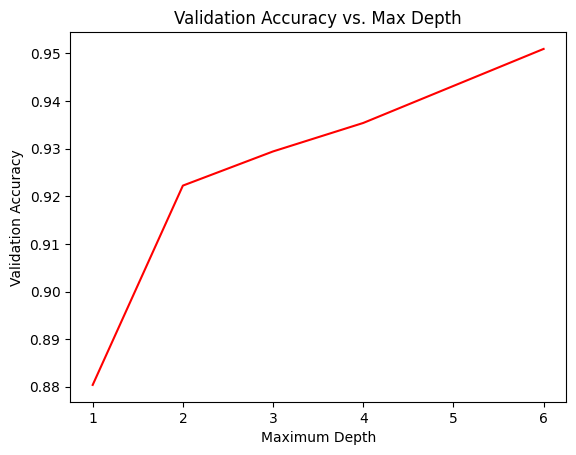

validation Accuracies: [0.8803827751196173, 0.9222488038277512, 0.9294258373205742, 0.9354066985645934, 0.9509569377990431]
max depth =  6
test Accuracies: 0.959378733572282


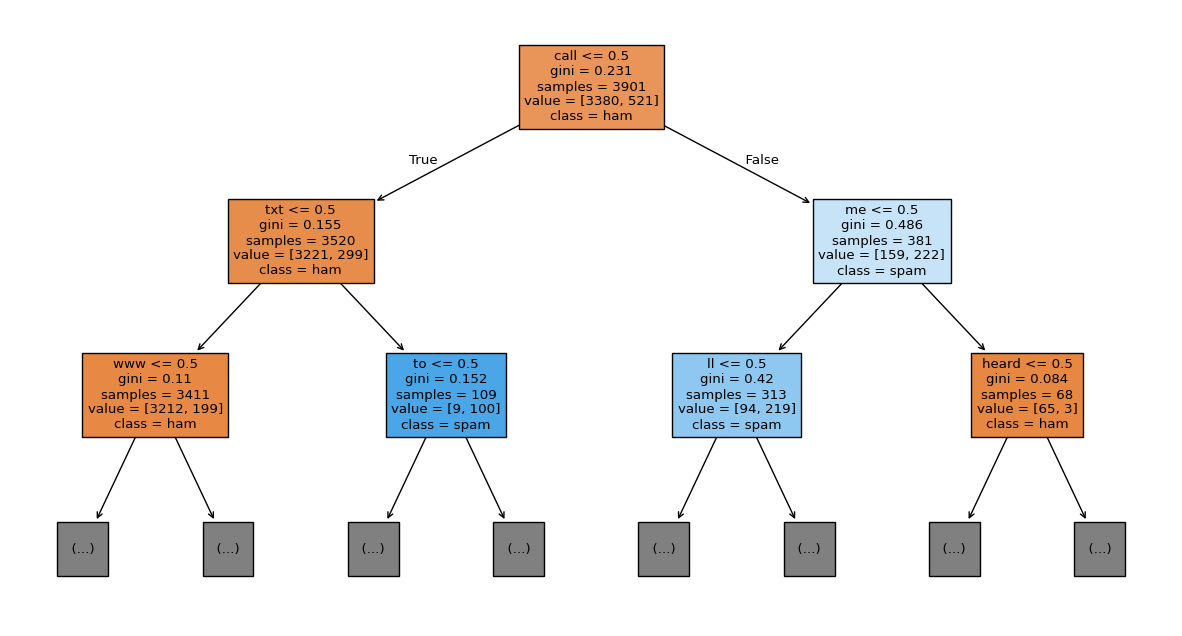

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

def load_data(file):
    #read csv
    df = pd.read_csv("sms.csv")

    labels = df["label"]
    messages = df["message"]

    #split by 70% train and 30% test
    x_train, x_test, y_train, y_test = train_test_split(
            messages, labels, test_size = 0.30, random_state = 42)


    #split 15 validation 15 test from 30 test
    x_val, x_test, y_val,y_test = train_test_split(
        x_test, y_test,test_size=0.50, random_state=42)


    vectorizer = CountVectorizer()
    #fit the vectorizer only for training set
    x_train_vectorizer = vectorizer.fit_transform(x_train)

    #just transform on validation and test set
    x_val_vectorizer = vectorizer.transform(x_val)
    x_test_vectorizer = vectorizer.transform(x_test)

    return vectorizer, x_train_vectorizer, x_test_vectorizer, x_val_vectorizer, y_train, y_test, y_val

def select_model(x_train, y_train, x_val, y_val, depths):
    accuracies = []

    for i in depths:
        #define model
        classifier = DecisionTreeClassifier(max_depth=i, random_state=42)

        #train model
        classifier.fit(x_train,y_train)

        #predict for validation messages
        y_predict = classifier.predict(x_val)
        accuracy = accuracy_score(y_val,y_predict)

        # store accuracies
        accuracies.append(accuracy)

    plt.plot(depths, accuracies, color = "red")
    plt.title("Validation Accuracy vs. Max Depth")
    plt.xlabel("Maximum Depth")
    plt.ylabel("Validation Accuracy")
    plt.show()

    return accuracies

vectorizer, x_train, x_test, x_val, y_train, y_test, y_val = load_data("sms.csv")

# pass the 5 depths
depths = [1,2,3,4,6]

accuracies = select_model(x_train, y_train, x_val, y_val, depths)

print("validation Accuracies:",accuracies)

max_depth_index = accuracies.index(max(accuracies))

# define the model for testing
classifier = DecisionTreeClassifier(max_depth=max_depth_index, random_state=42)

# train the model
classifier.fit(x_train,y_train)

y_predict = classifier.predict(x_test)
accuracy = accuracy_score(y_test, y_predict)

print("max depth = ", depths[max_depth_index])
print("test Accuracies:",accuracy)

plt.figure(figsize=(15, 8))

plot_tree(
    classifier,
    max_depth=2,
    feature_names=vectorizer.get_feature_names_out(),
    class_names=classifier.classes_.astype(str),
    filled=True
)

plt.show()
